In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
input_csv_name = "combined_segmentation_quality_v2.csv"
df = pd.read_csv(input_csv_name)
df

,image_id,dataset,model,n_true,n_predicted,count_error,TP,FP,FN,precision,...,intensity_p99,contrast,laplacian_variance,noise_estimate,n_cells,cell_density,foreground_fraction,mean_cell_area,median_cell_area,cell_area_cv
0,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2,23,23,0,23,0,0,1.000000,...,8822.707031,8822.707031,0.000413,0.005038,23,117.596531,0.096623,821.652174,797.0,0.406147
1,official_dataset/train/174_img.png,official_dataset/train,cpsam_v2,28,27,-1,25,2,3,0.925926,...,21321.542969,21138.451767,0.000495,0.006189,28,106.811523,0.149349,1398.250000,1412.5,0.499343
2,official_dataset/train/202_img.png,official_dataset/train,cpsam_v2,87,88,1,79,9,8,0.897727,...,35842.250000,34371.798828,0.003199,0.017183,87,465.539384,0.379613,815.425287,823.0,0.349453
3,official_dataset/train/212_img.png,official_dataset/train,cpsam_v2,142,141,-1,138,3,4,0.978723,...,40253.601562,40253.601562,0.007260,0.022528,142,747.557278,0.505744,676.528169,663.0,0.569253
4,official_dataset/train/457_img.png,official_dataset/train,cpsam_v2,86,82,-4,79,3,7,0.963415,...,37312.699219,33452.764893,0.006454,0.021545,86,1006.554307,0.939478,933.360465,891.0,0.709865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,60,68,8,60,8,0,0.882353,...,13318.000000,3739.000000,0.000156,0.002849,60,30.612245,0.024161,789.250000,758.0,0.263644
989,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,47,53,6,47,6,0,0.886792,...,13302.000000,3666.000000,0.000152,0.002752,47,23.979592,0.017869,745.191489,757.0,0.300658
990,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,92,102,10,91,11,1,0.892157,...,13513.000000,7081.000000,0.000165,0.003170,92,46.938776,0.033780,719.663043,697.0,0.317847
991,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,46,55,9,46,9,0,0.836364,...,13299.000000,3689.000000,0.000152,0.002735,46,23.469388,0.017001,724.391304,671.0,0.331508


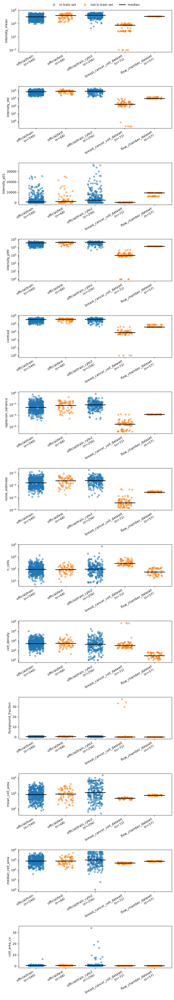

In [3]:
output_file_name = "features_by_dataset.pdf"

feature_list = [
    "intensity_mean", "intensity_std", "intensity_p01", "intensity_p99", "contrast",
    "laplacian_variance", "noise_estimate", "n_cells", "cell_density", "foreground_fraction",
    "mean_cell_area", "median_cell_area", "cell_area_cv",
]
log_axis = ["intensity_mean", "intensity_std", "intensity_p99", "contrast", "laplacian_variance",
            "noise_estimate", "n_cells", "cell_density", "mean_cell_area", "median_cell_area"]

in_train = ["official_dataset/train", "official_dataset/train_cyto2"]
blue = "tab:blue"
orange = "tab:orange"

def short(name):
    parts = name.split("/")
    return "official/" + parts[1] if parts[0] == "official_dataset" else parts[0]

datasets = list(df["dataset"].unique())
colors = [blue if d in in_train else orange for d in datasets]
labels = [f"{short(d)}\n(n={(df['dataset'] == d).sum()})" for d in datasets]

rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(feature_list), 1, figsize=(8, 3.5 * len(feature_list)))

for ax, feature in zip(axes, feature_list):
    for i, (d, c) in enumerate(zip(datasets, colors)):
        y = df.loc[df["dataset"] == d, feature].dropna()
        x = i + rng.uniform(-0.25, 0.25, len(y))                  # jitter
        ax.scatter(x, y, s=20, facecolor=to_rgba(c, 0.3), edgecolor=c, linewidth=1)
        ax.hlines(y.median(), i - 0.35, i + 0.35, color="black", linewidth=2)  # median
    if feature in log_axis:
        ax.set_yscale("log")
    ax.set_ylabel(feature)
    ax.set_xticks(range(len(datasets)))
    ax.set_xticklabels(labels, rotation=30, ha="right")

handles = [
    Line2D([], [], marker="o", linestyle="", markerfacecolor=to_rgba(blue, 0.3),
           markeredgecolor=blue, label="in train set"),
    Line2D([], [], marker="o", linestyle="", markerfacecolor=to_rgba(orange, 0.3),
           markeredgecolor=orange, label="not in train set"),
    Line2D([], [], color="black", linewidth=2, label="median"),
]
axes[0].legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)

fig.tight_layout()
fig.savefig(output_file_name)
plt.show()

c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


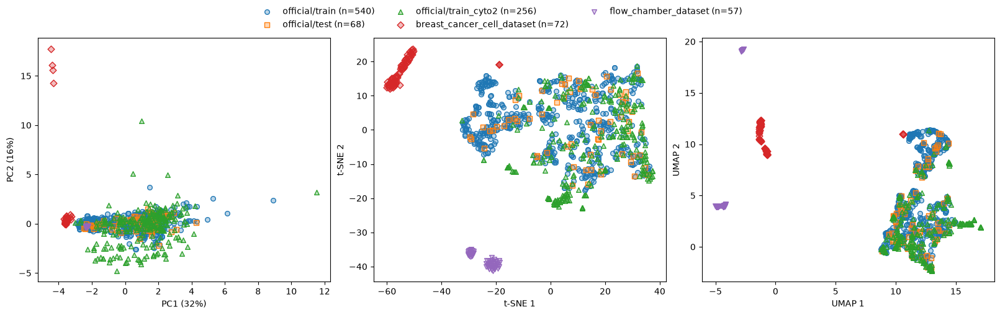

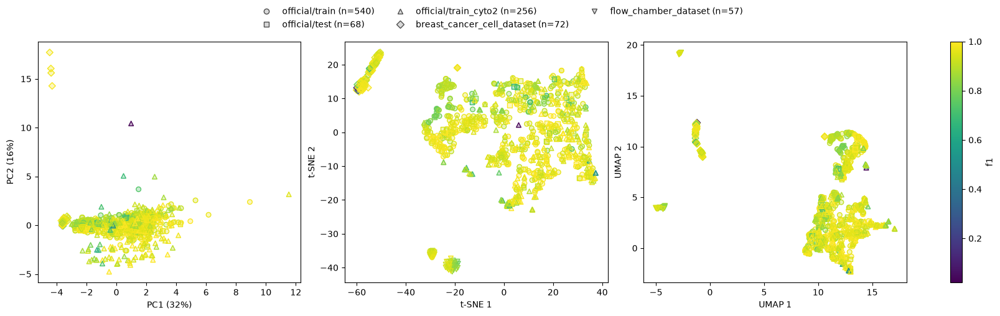

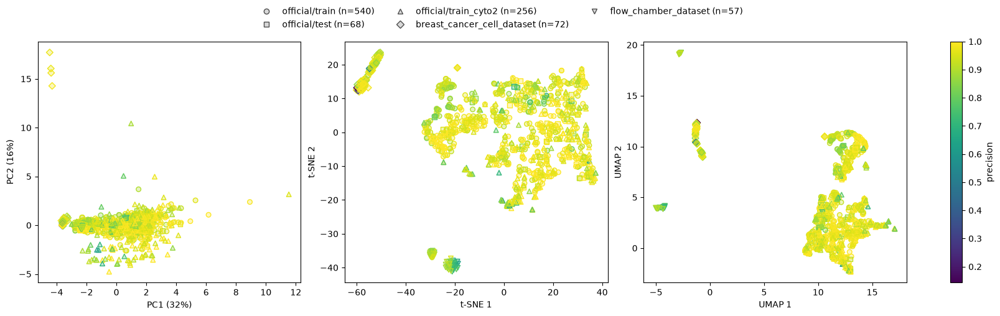

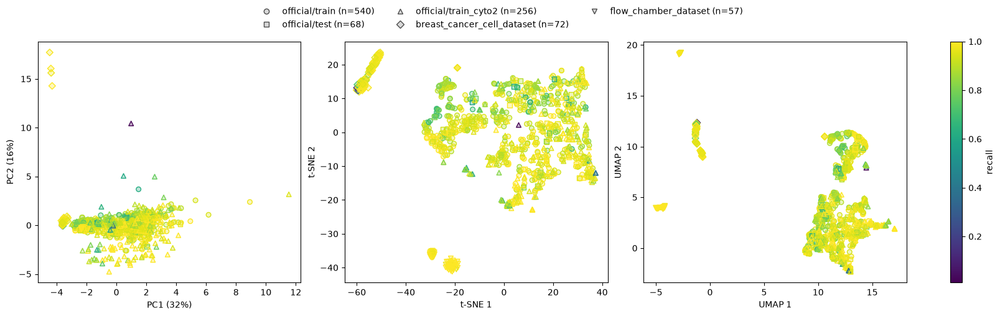

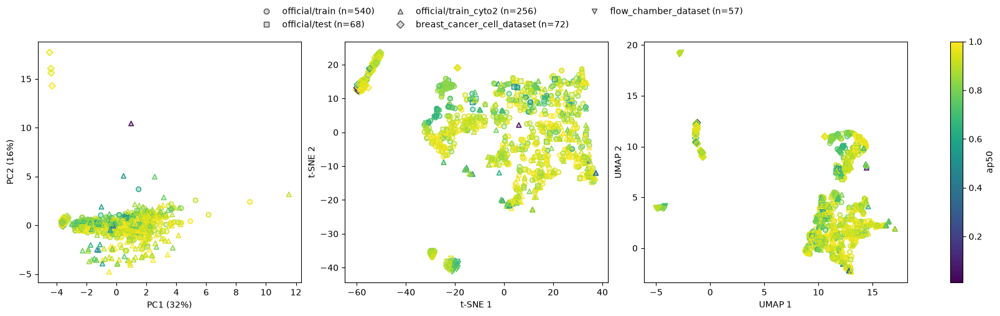

...

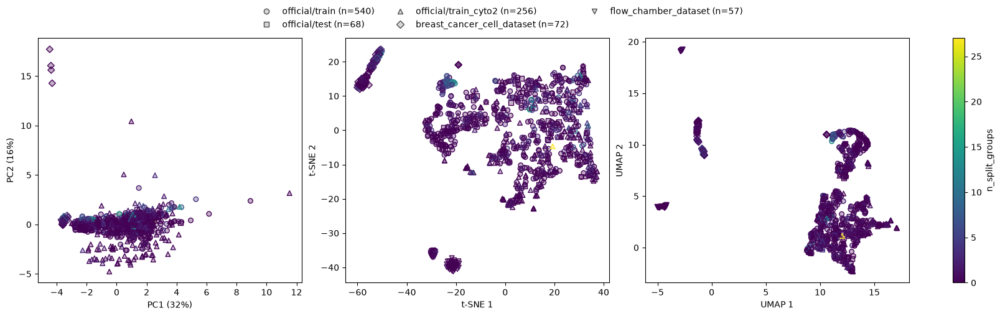

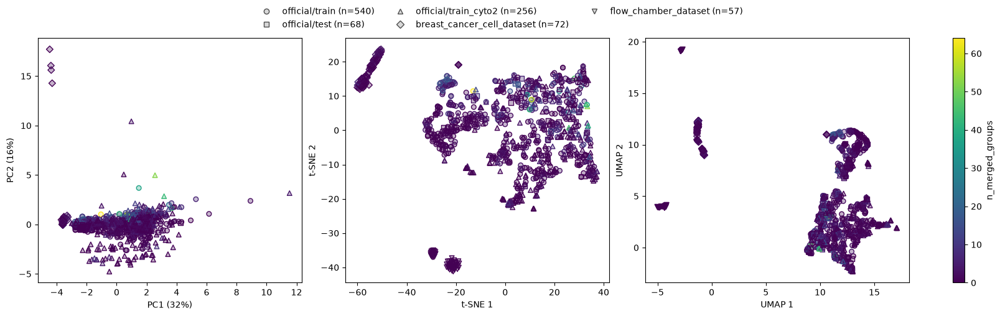

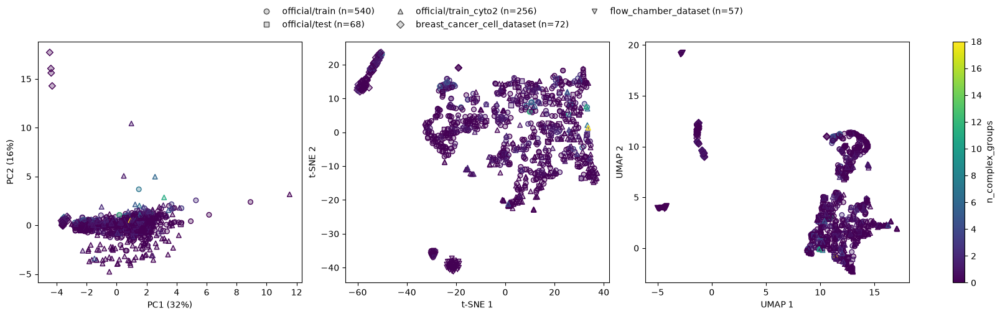

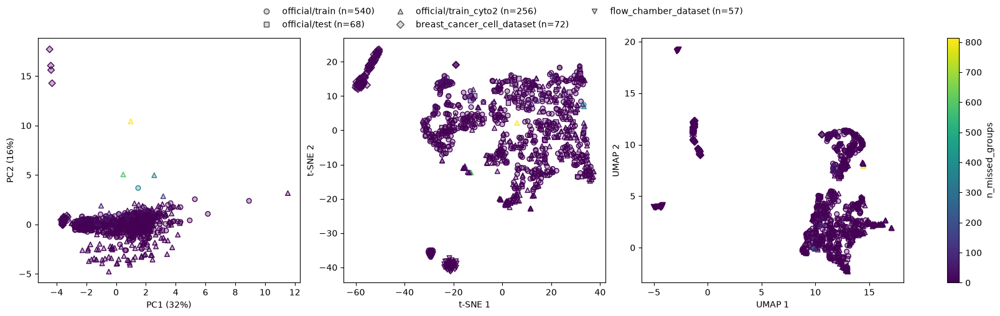

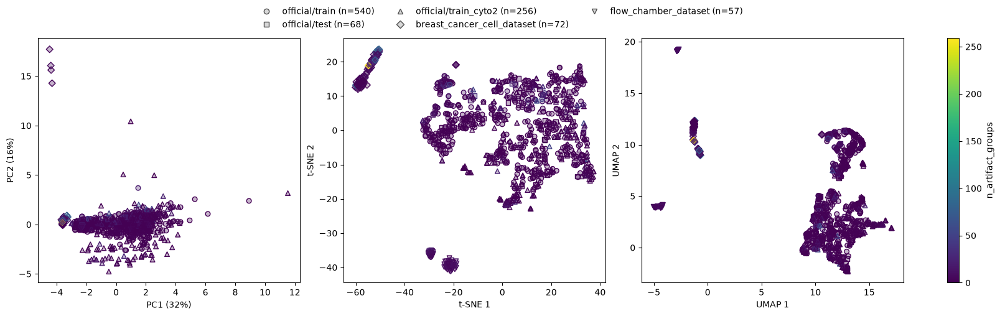

In [5]:
METRICS_LIST = [
    "f1", "precision", "recall", "ap50", "ap75", "ap90", "count_error",
    "mean_iou", "median_iou", "mean_dice", "foreground_iou", "foreground_dice",
    "aji_custom", "aji_official",
    "b_f1_50", "b_f1_75", "b_f1_90",
    "n_split_groups", "n_merged_groups", "n_complex_groups", "n_missed_groups", "n_artifact_groups",
]
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]  
CMAP = plt.get_cmap("viridis").copy()
CMAP.set_bad("lightgrey")   

meta = df.dropna(subset=feature_list).reset_index(drop=True)
X_feat = StandardScaler().fit_transform(meta[feature_list])

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_feat)
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X_feat)
X_umap = umap.UMAP(n_components=2, random_state=0).fit_transform(X_feat)

spaces = [ 
    (X_pca, f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"),
    (X_tsne, "t-SNE 1", "t-SNE 2"),
    (X_umap, "UMAP 1", "UMAP 2"),
]

labels = meta["dataset"].map(short)
datasets = list(labels.unique())
marker_of = {d: MARKERS[i] for i, d in enumerate(datasets)}
color_of = {d: plt.cm.tab10(i) for i, d in enumerate(datasets)}
masks = {d: (labels == d).to_numpy() for d in datasets}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (X, xl, yl) in zip(axes, spaces):
    for d in datasets:
        m, c = masks[d], color_of[d]
        ax.scatter(X[m, 0], X[m, 1], s=30, marker=marker_of[d], facecolor=to_rgba(c, 0.3),
                   edgecolor=c, linewidth=1, label=f"{d} (n={m.sum()})")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside upper center", ncol=3, frameon=False)
plt.show()

legend_handles = [
    Line2D([], [], marker=marker_of[d], linestyle="", markerfacecolor=(0.5, 0.5, 0.5, 0.3),
           markeredgecolor="0.3", label=f"{d} (n={masks[d].sum()})")
    for d in datasets
]

for metric in METRICS_LIST:
    values = meta[metric].to_numpy(dtype=float)
    norm = Normalize(np.nanmin(values), np.nanmax(values))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for ax, (X, xl, yl) in zip(axes, spaces):
        for d in datasets:
            m = masks[d]
            edge = CMAP(norm(values[m]))              # solid border in the metric colour
            face = edge.copy()
            face[:, 3] = 0.3                          # fill with alpha = 0.3
            ax.scatter(X[m, 0], X[m, 1], s=30, marker=marker_of[d], facecolor=face, edgecolor=edge, linewidth=1)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)

    fig.legend(handles=legend_handles, loc="outside upper center", ncol=3, frameon=False)
    fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP), ax=axes, label=metric)
    plt.show()

In [ ]:
THRESHOLD = 0.3

low = df[df["aji_official"] < THRESHOLD]
rest = df[df["aji_official"] >= THRESHOLD]
print(f"aji_official < {THRESHOLD}: n = {len(low)} | rest: n = {len(rest)}")

stats = ["mean", "median", "min", "max"]
table = pd.concat(
    {f"aji_official < {THRESHOLD}": low[feature_list].agg(stats).T,
     "rest": rest[feature_list].agg(stats).T},
    axis=1,
)
display(table)

aji_official < 0.3: n = 10 | rest: n = 983


aji_official < 0.3                                rest  \
                                  mean   median      min      max     mean   
intensity_mean                4.98e+03 4.97e+03     61.3 1.62e+04 1.35e+04   
intensity_std                 3.45e+03 2.38e+03      131 9.54e+03 6.69e+03   
intensity_p01                 2.25e+03  1.2e+03        0 1.05e+04 3.39e+03   
intensity_p99                 1.86e+04    2e+04      651 4.17e+04 3.09e+04   
contrast                      1.64e+04 1.32e+04      643 4.03e+04 2.75e+04   
laplacian_variance             0.00273  0.00167 1.43e-07  0.00764   0.0135   
noise_estimate                  0.0122   0.0105 0.000148   0.0315   0.0217   
n_cells                            334      110       41  1.8e+03      145   
cell_density                       764      413     68.4 4.79e+03 1.04e+03   
foreground_fraction              0.907    0.999   0.0753        1    0.613   
mean_cell_area                4.45e+03 2.24e+03      209 1.46e+04 1.28e+03   
median_cell_area                   446      132       37 1.79e+03 1.19e+03   
cell_area_cv                      11.8     8.09     0.34     34.1     0.56   

                                                 
                      median       min      max  
intensity_mean      1.14e+04    0.0971 5.29e+04  
intensity_std       7.02e+03     0.204 1.92e+04  
intensity_p01            969 -4.95e-10 3.65e+04  
intensity_p99       3.53e+04         1 6.08e+04  
contrast            3.11e+04         1 6.08e+04  
laplacian_variance   0.00297  1.33e-07    0.736  
noise_estimate        0.0162  0.000142    0.173  
n_cells                   95         5 7.21e+03  
cell_density             434      8.16 7.44e+04  
foreground_fraction     0.48   0.00581     37.6  
mean_cell_area           783      49.8 1.02e+04  
median_cell_area         719         1 6.62e+03  
cell_area_cv             0.5    0.0709     19.2

c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


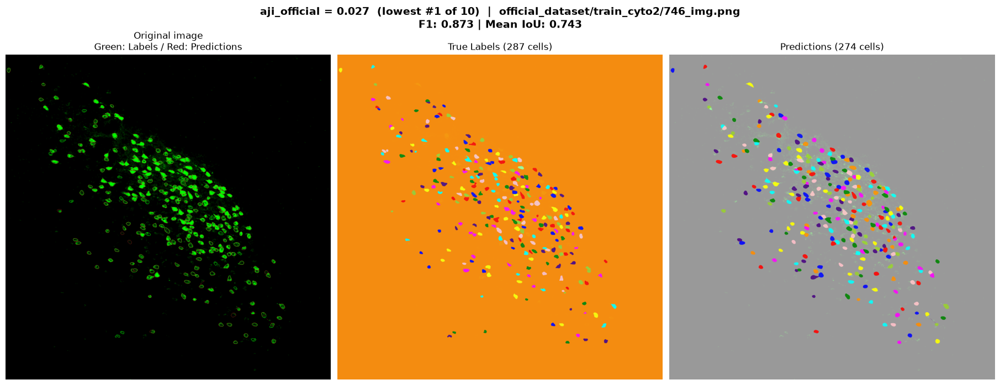

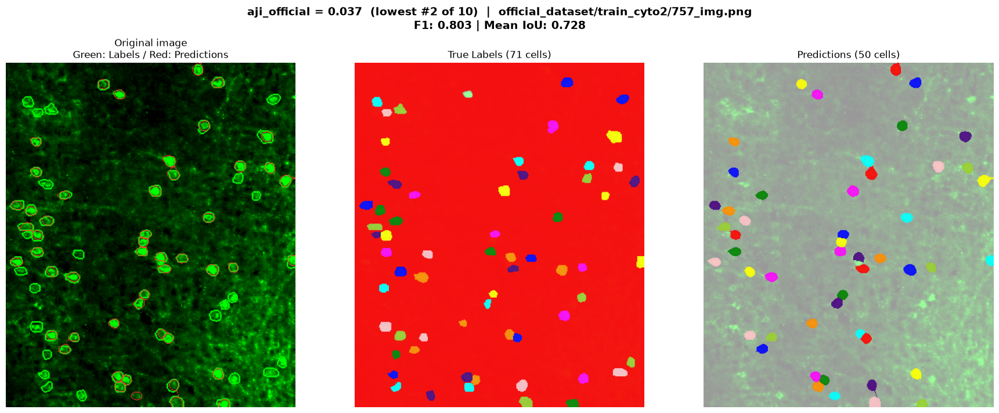

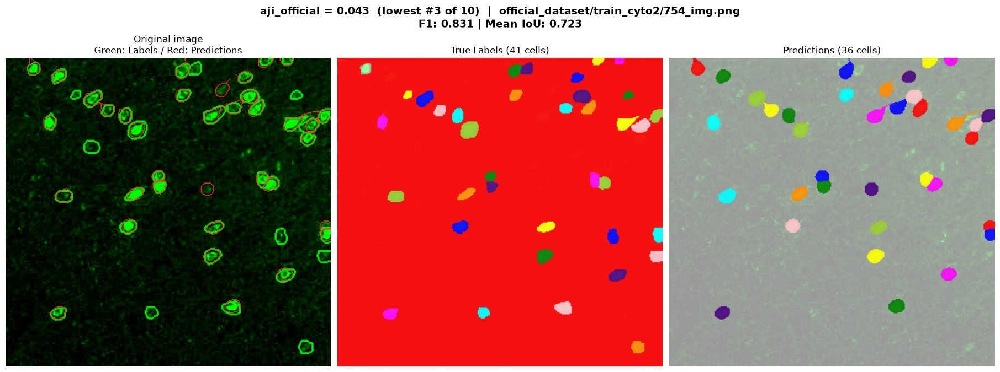

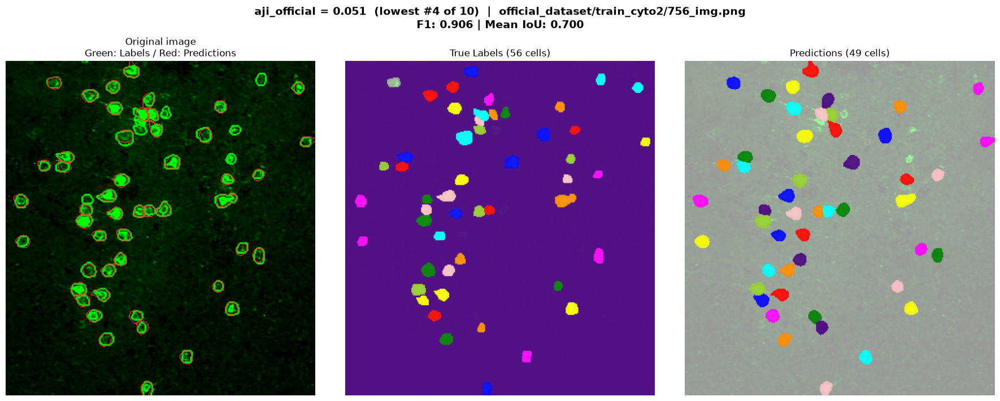

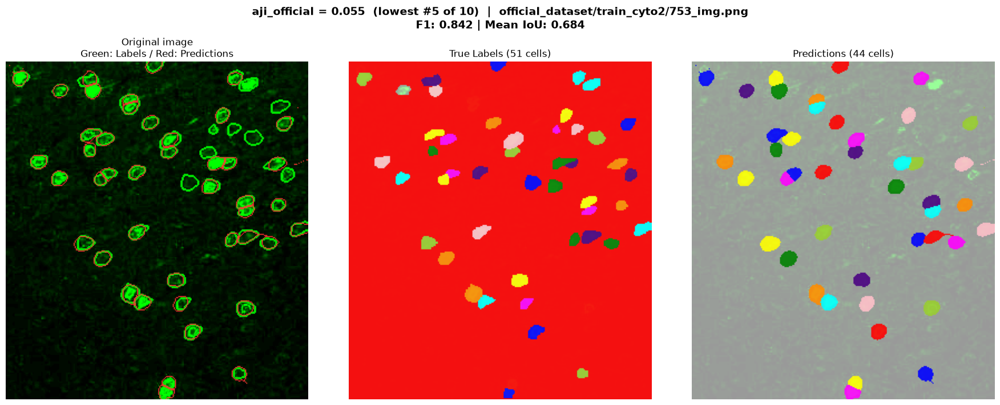

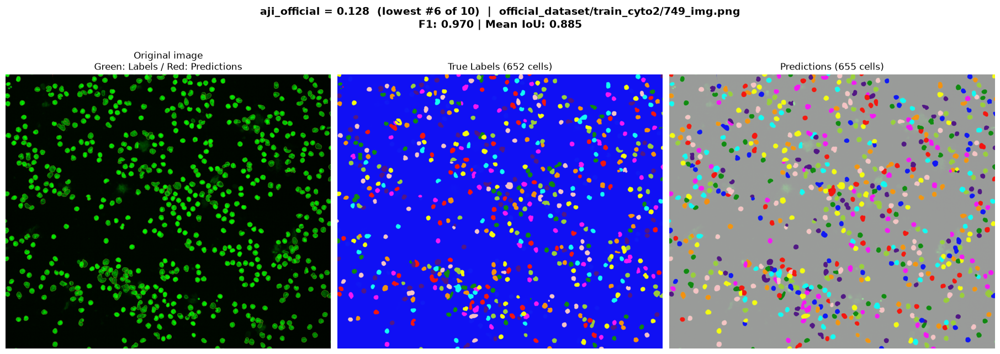

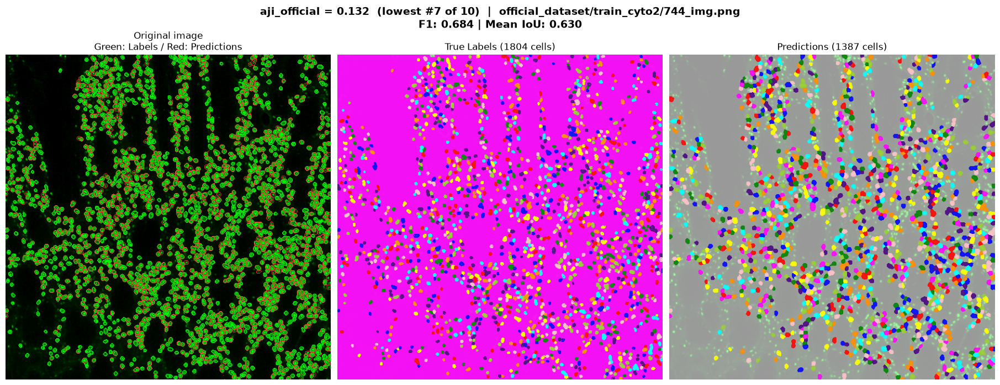

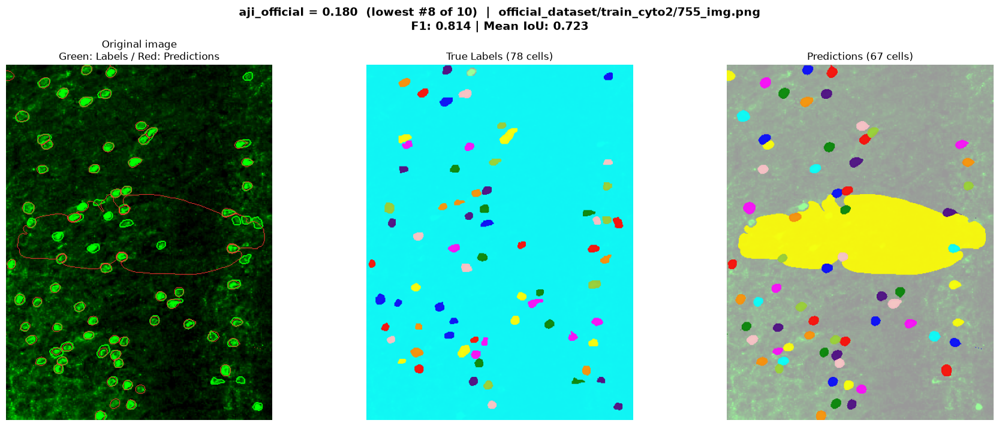

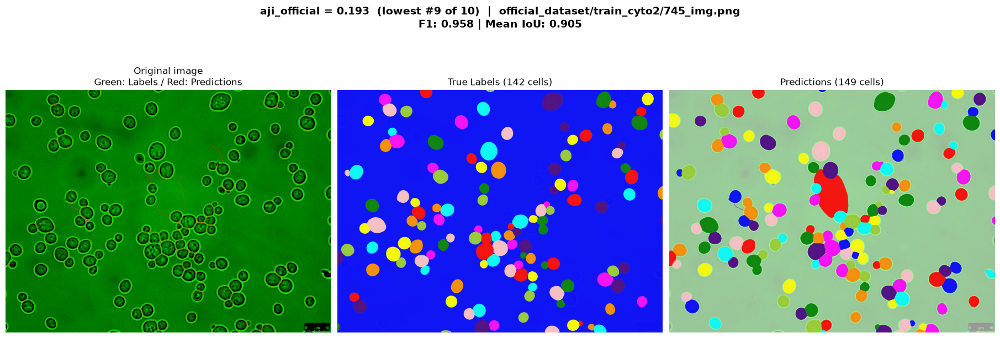

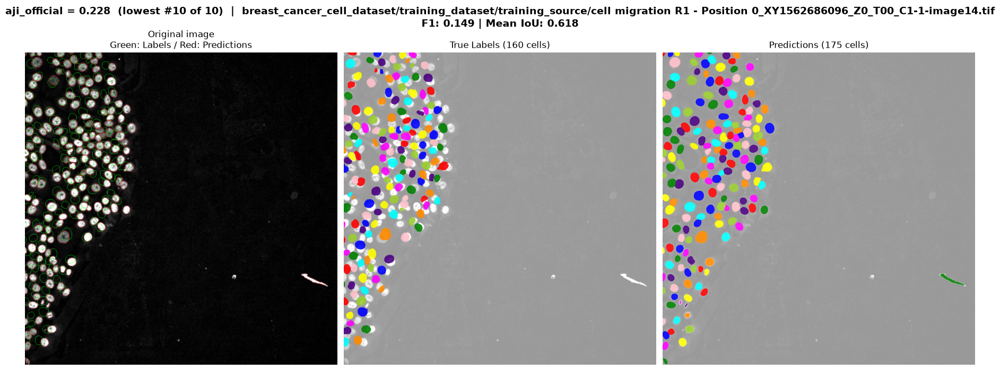

In [ ]:
from pathlib import Path
import torch
from cellpose import models, io
from skimage.segmentation import find_boundaries
from skimage.color import label2rgb

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cp_model = models.CellposeModel(pretrained_model="cpsam_v2", device=device)

def to_display(img):
    """Scale each channel to 0-1 for display (the model still gets the raw image)."""
    img = img.astype(float)
    if img.ndim == 2:                         
        img = np.stack([img] * 3, axis=-1)
    out = np.zeros((*img.shape[:2], 3))
    for c in range(min(3, img.shape[-1])):
        lo, hi = np.percentile(img[..., c], (1, 99))
        if hi > lo:                          
            out[..., c] = np.clip((img[..., c] - lo) / (hi - lo), 0, 1)
    return out

# --- Show every image of the low subset ---
for rank, (_, row) in enumerate(low.sort_values("aji_official").iterrows(), start=1):
    image_id = row["image_id"]

    image_path = Path(image_id.replace(":", "_"))
    if "_img" in image_path.name:                                      
        mask_path = image_path.parent / image_path.name.replace("img", "masks")
    else:                                                            
        mask_path = image_path.parent.parent / "training_target" / image_path.name

    # read and predict
    image = io.imread(image_path)
    true_cells = io.imread(mask_path)
    predicted_cells, _, _ = cp_model.eval(image)

    rgb = to_display(image)
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True, sharey=True, constrained_layout=True)
    ax_input, ax_true, ax_pred = axes

    ax_input.imshow(rgb)
    true_edges = np.zeros((*true_cells.shape, 4))
    pred_edges = np.zeros((*predicted_cells.shape, 4))
    true_edges[find_boundaries(true_cells, mode="inner")] = [0, 1, 0, 0.9]
    pred_edges[find_boundaries(predicted_cells, mode="inner")] = [1, 0.2, 0.2, 0.9]
    ax_input.imshow(true_edges)
    ax_input.imshow(pred_edges)
    ax_input.set_title("Original image\nGreen: Labels / Red: Predictions")

    for ax, cells, title in [(ax_true, true_cells, "True Labels"), (ax_pred, predicted_cells, "Predictions")]:
        ax.imshow(rgb, alpha=0.4)
        overlay = np.dstack([label2rgb(cells, bg_label=0), (cells > 0) * 0.9])
        ax.imshow(overlay)
        ax.set_title(f"{title} ({len(np.unique(cells)) - 1} cells)")

    for ax in axes:
        ax.set_axis_off()

    fig.suptitle(f"aji_official = {row['aji_official']:.3f}  (lowest #{rank} of {len(low)})  |  {image_id}\n",
                 fontsize=14)
    plt.show()